#  Horse Image Segmentation: Baseline Encoder–Decoder vs U-Net

## 1. Project Introduction and Objectives

### What is Image Segmentation?

**Image segmentation** is a computer vision task where the goal is to classify *every pixel* in an image.
Unlike image classification (which assigns one label to the whole image) or object detection (which draws
bounding boxes), segmentation produces a **pixel-level map** showing exactly which pixels belong to each object.

### Binary Segmentation

In **binary segmentation**, there are only two classes:
- **Foreground** — the object of interest (in our case, the horse)
- **Background** — everything else

The output is a **binary mask**: a single-channel image where each pixel is either 0 (background) or 1 (foreground).

### Encoder–Decoder Architecture

An **encoder** progressively reduces spatial resolution while increasing the number of feature channels,
capturing *what* is in the image but losing *where* exactly it is. A **decoder** does the reverse: it
upsamples the compressed representation back to the original resolution to produce a per-pixel prediction.

### Skip Connections and U-Net

**Skip connections** directly link encoder layers to corresponding decoder layers at the same resolution.
They allow the decoder to recover fine spatial details that were lost during downsampling.

**U-Net** is a famous architecture that adds these skip connections to the standard encoder–decoder design.

### Research Question

> *"Do skip connections help a segmentation model recover object boundaries and produce better horse
> masks than an encoder–decoder model without skip connections?"*

### Fair Comparison

To answer this fairly, both models will use:
- The **same dataset split** (train / validation / test)
- The **same loss function** (Binary Cross-Entropy with Logits)
- The **same optimizer, learning rate, and training epochs**
- The **same evaluation metrics** (IoU, F1, Precision, Recall)

## 2. Imports and Configuration

We begin by importing all necessary libraries and setting up reproducible hyperparameters.

**Key concepts:**
- **Random seed**: Fixes the random number generator so results are reproducible across runs.
- **Device**: PyTorch can run on CPU or GPU (CUDA). We auto-detect what's available.
- **Batch size**: Number of images processed together in one forward/backward pass. Larger = faster but uses more memory.
- **Learning rate**: Controls how much the model weights change after each batch. Too high = unstable; too low = slow convergence.
- **Epochs**: One epoch = one full pass through the entire training set.
- **Patience**: For early stopping — if validation loss doesn't improve for this many epochs, we stop training to prevent overfitting.

In [3]:
import sys
import os
from pathlib import Path
import json
import random
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Try importing tqdm for progress bars; fall back to a simple wrapper
try:
    from tqdm import tqdm
except ImportError:
    def tqdm(iterable, **kwargs):
        return iterable

import pandas as pd

print("All imports successful!")
print(f"PyTorch version: {torch.__version__}")

All imports successful!
PyTorch version: 2.6.0+cu124


In [4]:
# ── Reproducibility ──────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ── Device ───────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ── Hyperparameters ──────────────────────────────────────────────────
IMAGE_SIZE = 256          # Images are already 256×256
BATCH_SIZE = 8            # 8 images per batch
LEARNING_RATE = 1e-3      # Adam default; good starting point
NUM_EPOCHS = 50           # Maximum training epochs
PATIENCE = 10             # Early stopping patience

# ── Paths ────────────────────────────────────────────────────────────
CODE_DIR = Path(".").resolve()          # code/ folder
PROJECT_ROOT = CODE_DIR.parent         # CS3103_ML_Proj/
OUTPUT_DIR = CODE_DIR / "outputs"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
PREDICTION_DIR = OUTPUT_DIR / "predictions"

# Create output directories
for d in [CHECKPOINT_DIR, PLOT_DIR, PREDICTION_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Device:         {DEVICE}")
print(f"Seed:           {SEED}")
print(f"Batch size:     {BATCH_SIZE}")
print(f"Learning rate:  {LEARNING_RATE}")
print(f"Max epochs:     {NUM_EPOCHS}")
print(f"Early stopping: {PATIENCE} epochs patience")
print(f"Output dir:     {OUTPUT_DIR}")

Device:         cuda
Seed:           42
Batch size:     8
Learning rate:  0.001
Max epochs:     50
Early stopping: 10 epochs patience
Output dir:     C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs


## 3. Load the Existing Processed Dataset

We reuse the existing `dataset.py` which:
1. Has already preprocessed images to 256×256 RGB PNGs.
2. Has already created binary masks (horse = white = 1, background = black = 0).
3. Has saved a deterministic 80:10:10 split in `splits.json`.

We import the `HorseSegmentationDataset` class and create DataLoaders for each split.

In [5]:
# Make sure we can import dataset.py from the code/ folder
sys.path.insert(0, str(CODE_DIR))
from dataset import HorseSegmentationDataset

# Create datasets
train_dataset = HorseSegmentationDataset("train")
val_dataset   = HorseSegmentationDataset("val")
test_dataset  = HorseSegmentationDataset("test")

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Training samples:   {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples:       {len(test_dataset)}")
print(f"Training batches:   {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Test batches:       {len(test_loader)}")

Training samples:   261
Validation samples: 32
Test samples:       34
Training batches:   33
Validation batches: 4
Test batches:       5


In [6]:
# ── Verify tensor shapes, dtypes, and value ranges ──────────────────
sample_img, sample_mask = train_dataset[0]

print("=== Tensor Verification ===")
print(f"Image shape:  {sample_img.shape}    (expected: [3, 256, 256])")
print(f"Mask shape:   {sample_mask.shape}   (expected: [1, 256, 256])")
print(f"Image dtype:  {sample_img.dtype}    (expected: torch.float32)")
print(f"Mask dtype:   {sample_mask.dtype}   (expected: torch.float32)")
print(f"Image range:  [{sample_img.min().item():.4f}, {sample_img.max().item():.4f}]  (expected: [0, 1])")
print(f"Mask unique:  {torch.unique(sample_mask).tolist()}  (expected: [0.0, 1.0])")

# Verify spatial dimensions match
assert sample_img.shape[1:] == sample_mask.shape[1:], \
    f"Spatial mismatch: image {sample_img.shape[1:]} vs mask {sample_mask.shape[1:]}"
print("\n✓ Image and mask spatial dimensions match.")

# Verify no duplicate filenames across splits
train_set = set(train_dataset.filenames)
val_set   = set(val_dataset.filenames)
test_set  = set(test_dataset.filenames)
assert len(train_set & val_set) == 0, "Overlap between train and val!"
assert len(train_set & test_set) == 0, "Overlap between train and test!"
assert len(val_set & test_set) == 0, "Overlap between val and test!"
print("✓ No overlapping filenames across splits.")

# Verify masks contain both classes
has_fg = sample_mask.max().item() > 0
print(f"✓ Sample mask contains foreground pixels: {has_fg}")
print("\nAll dataset checks passed!")

=== Tensor Verification ===
Image shape:  torch.Size([3, 256, 256])    (expected: [3, 256, 256])
Mask shape:   torch.Size([1, 256, 256])   (expected: [1, 256, 256])
Image dtype:  torch.float32    (expected: torch.float32)
Mask dtype:   torch.float32   (expected: torch.float32)
Image range:  [0.0000, 1.0000]  (expected: [0, 1])
Mask unique:  [0.0, 1.0]  (expected: [0.0, 1.0])

✓ Image and mask spatial dimensions match.
✓ No overlapping filenames across splits.
✓ Sample mask contains foreground pixels: True

All dataset checks passed!


## 4. Display Preprocessed Images and Masks

- Images have **3 channels** (Red, Green, Blue) — standard color representation.
- Masks have **1 channel** — a grayscale map where each pixel is 0 or 1.

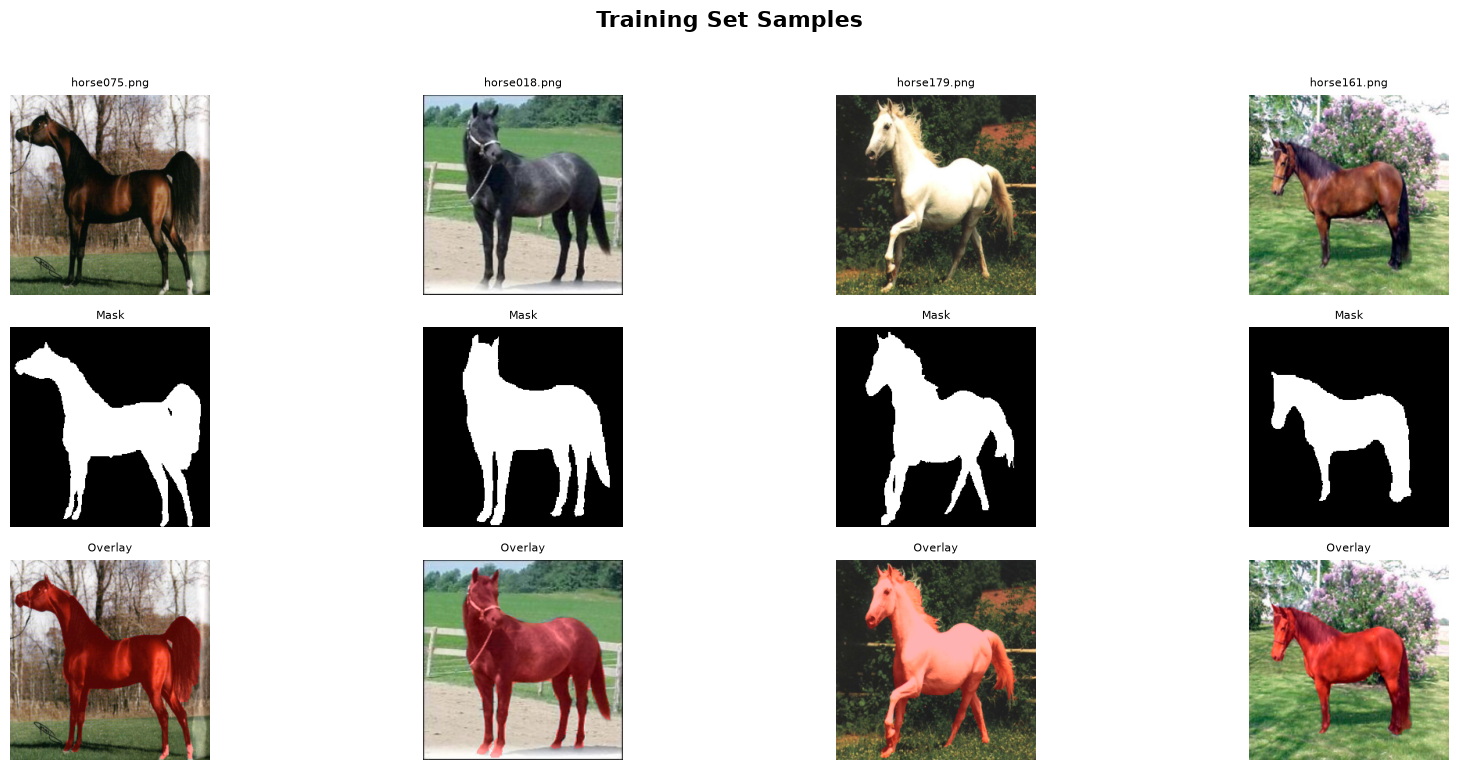

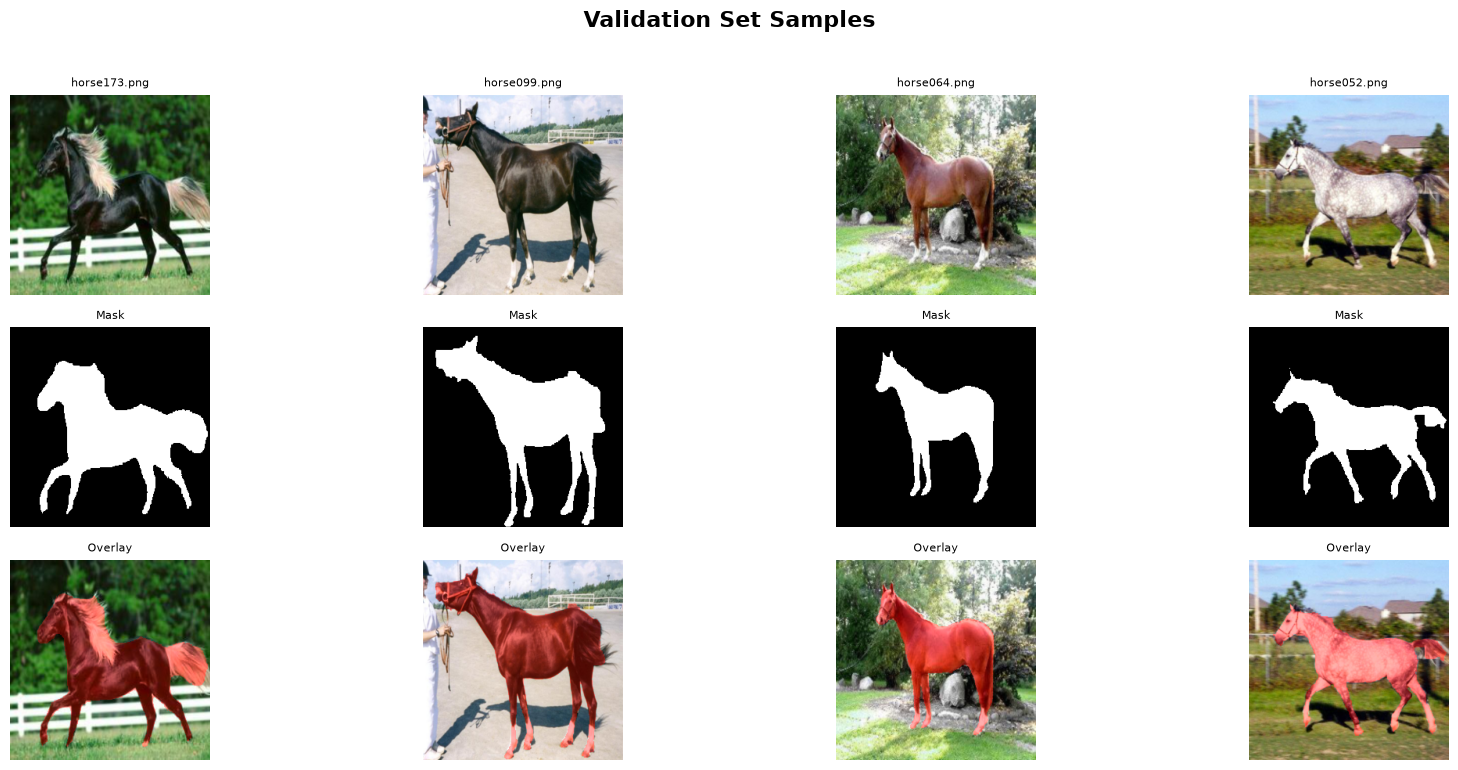

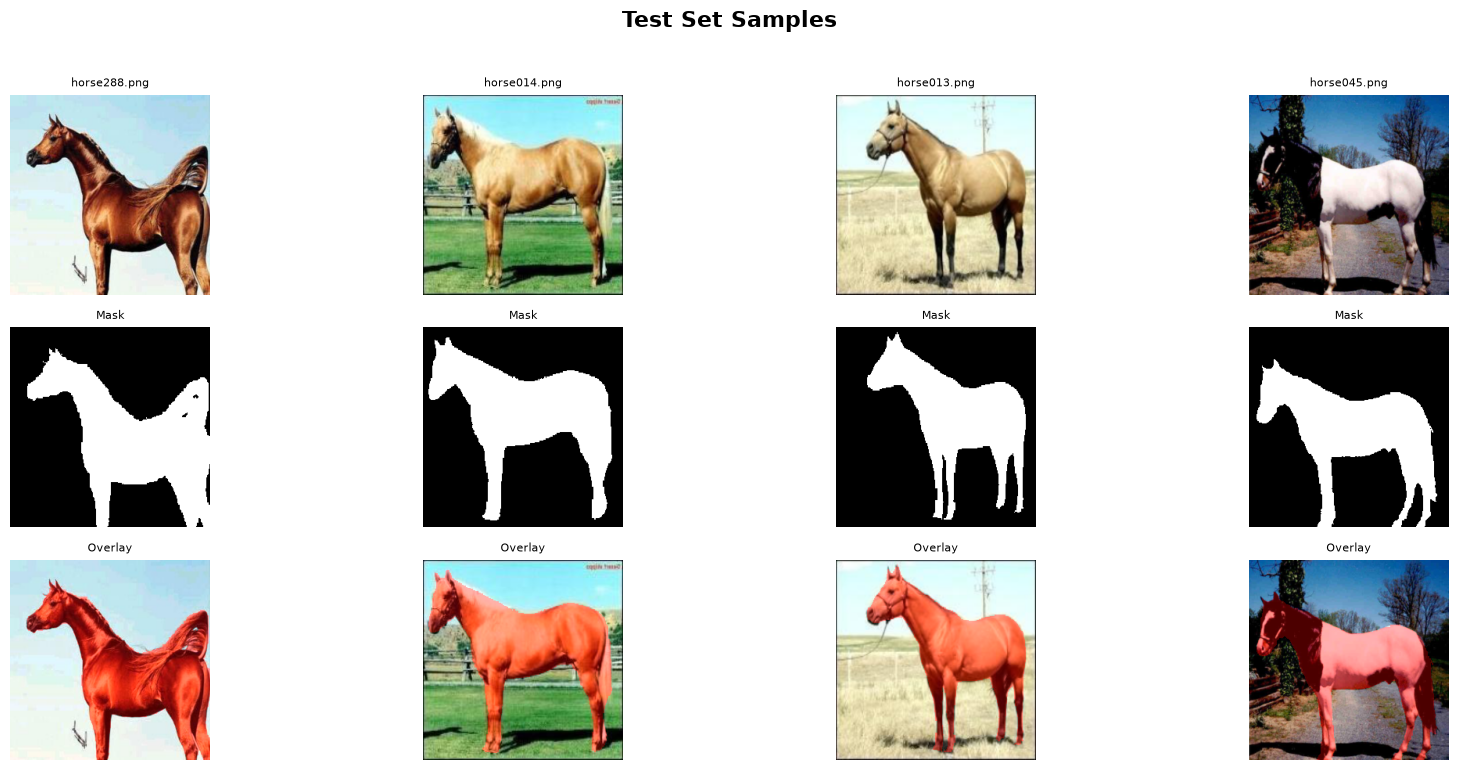

In [25]:
def show_samples(dataset, title, num_samples=8, figsize=(18, 2.5)):
    """Display image, mask, and overlay for random samples from a dataset."""
    indices = random.sample(range(len(dataset)), min(num_samples, len(dataset)))

    fig, axes = plt.subplots(3, len(indices), figsize=(figsize[0], figsize[1] * 3))
    fig.suptitle(title, fontsize=16, fontweight='bold', y=1.02)

    for col, idx in enumerate(indices):
        img, mask = dataset[idx]
        # Convert tensors for display: CHW → HWC
        img_np = img.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze(0).numpy()

        # Row 0: Original image
        axes[0, col].imshow(img_np)
        axes[0, col].set_title(dataset.filenames[idx], fontsize=8)
        axes[0, col].axis('off')

        # Row 1: Binary mask
        axes[1, col].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
        axes[1, col].set_title('Mask', fontsize=8)
        axes[1, col].axis('off')

        # Row 2: Overlay — mask as transparent red on the image
        overlay = img_np.copy()
        horse_pixels = mask_np > 0.5
        overlay[horse_pixels, 0] = np.clip(overlay[horse_pixels, 0] + 0.3, 0, 1)
        overlay[horse_pixels, 1] = overlay[horse_pixels, 1] * 0.7
        overlay[horse_pixels, 2] = overlay[horse_pixels, 2] * 0.7
        axes[2, col].imshow(overlay)
        axes[2, col].set_title('Overlay', fontsize=8)
        axes[2, col].axis('off')

    axes[0, 0].set_ylabel('Image', fontsize=12)
    axes[1, 0].set_ylabel('Mask', fontsize=12)
    axes[2, 0].set_ylabel('Overlay', fontsize=12)

    plt.tight_layout()
    plt.show()

# Display training, validation, and test examples
random.seed(SEED) 
show_samples(train_dataset, "Training Set Samples", num_samples=4)
show_samples(val_dataset, "Validation Set Samples", num_samples=4)
show_samples(test_dataset, "Test Set Samples", num_samples=4)

## 5. Understanding the Segmentation Pipeline

The complete segmentation pipeline works as follows:

```
RGB Image [3, 256, 256]
    │
    ▼
┌──────────┐
│  ENCODER  │  ← Extracts features, reduces spatial size
└──────────┘
    │
    ▼
┌────────────┐
│ BOTTLENECK │  ← Compressed representation (small spatial, many channels)
└────────────┘
    │
    ▼
┌──────────┐
│  DECODER  │  ← Reconstructs spatial resolution
└──────────┘
    │
    ▼
Logits [1, 256, 256]     ← Raw (unnormalized) scores per pixel
    │
    ▼
σ(logits) → Probabilities  ← Sigmoid converts to [0, 1] range
    │
    ▼
Threshold (≥ 0.5) → Binary Mask  ← Final prediction: 0 or 1
```

### Probability vs Binary Prediction

The model outputs a **logit** for each pixel (e.g., 2.1). We apply **sigmoid** to get a probability
(e.g., σ(2.1) = 0.89). We then **threshold** at 0.5:
- If probability ≥ 0.5 → predict **foreground** (horse)
- If probability < 0.5 → predict **background**

For example: a pixel with probability 0.82 is confidently predicted as horse, while 0.12 is confidently background.

## 6. Shared Building Blocks

Both models will share the same basic building blocks. This avoids code duplication and ensures a fair comparison.

### What each block does:

- **ConvBlock**: Two 3×3 convolutions, each followed by Batch Normalization and ReLU. This is the core
  feature extraction unit. Each convolution learns spatial patterns (edges, textures, shapes).

- **Batch Normalization**: Normalizes activations within each mini-batch. Stabilizes training and allows
  higher learning rates.

- **ReLU** (Rectified Linear Unit): `max(0, x)`. Introduces non-linearity — without it, stacking layers
  would just be a single linear transformation.

- **Max Pooling** (2×2, stride 2): Takes the maximum value in each 2×2 window, reducing spatial dimensions
  by half. This creates a **hierarchy of features**: early layers detect edges, deeper layers detect parts
  and objects.

- **ConvTranspose2d**: "Learnable upsampling" — doubles spatial dimensions. The reverse of downsampling.

### Why channels increase during encoding:
As spatial resolution shrinks (256→128→64→32→16), we compensate by increasing channels (32→64→128→256→512).
The encoder trades *spatial detail* for *semantic richness*.

In [8]:
class ConvBlock(nn.Module):
    """Two consecutive 3x3 convolutions, each followed by BatchNorm and ReLU.

    This is the fundamental feature extraction unit used in both models.
    Padding=1 ensures the spatial dimensions stay the same after each conv.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class EncoderBlock(nn.Module):
    """Downsampling block: MaxPool to halve spatial dims, then ConvBlock.

    Returns both the downsampled features (for the next level) and
    the pre-pooling features (for potential skip connections in U-Net).
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv = ConvBlock(in_channels, out_channels)

    def forward(self, x):
        x = self.pool(x)
        x = self.conv(x)
        return x


class DecoderBlock(nn.Module):
    """Upsampling block for the BASELINE (no skip connections).

    Uses ConvTranspose2d to double spatial dims, then ConvBlock.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = ConvBlock(out_channels, out_channels)

    def forward(self, x):
        x = self.up(x)
        x = self.conv(x)
        return x


class UNetDecoderBlock(nn.Module):
    """Upsampling block for U-Net WITH skip connections.

    1. Upsample the input features.
    2. Concatenate with the corresponding encoder features (skip connection).
    3. Apply ConvBlock to combine the information.

    The input to ConvBlock has (out_channels + out_channels) channels
    because we concatenate upsampled features and skip features.
    """
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        # After concat: out_channels (from up) + out_channels (from skip) = 2 * out_channels
        self.conv = ConvBlock(out_channels * 2, out_channels)

    def forward(self, x, skip):
        x = self.up(x)
        # Handle potential size mismatch (e.g., odd dimensions)
        if x.shape != skip.shape:
            x = nn.functional.interpolate(x, size=skip.shape[2:], mode='bilinear', align_corners=True)
        x = torch.cat([skip, x], dim=1)  # Concatenate along channel dimension
        x = self.conv(x)
        return x


print("Building blocks defined:")
print("  • ConvBlock       — Two 3x3 convolutions + BatchNorm + ReLU")
print("  • EncoderBlock    — MaxPool + ConvBlock (downsampling)")
print("  • DecoderBlock    — ConvTranspose2d + ConvBlock (upsampling, no skip)")
print("  • UNetDecoderBlock — ConvTranspose2d + Concat skip + ConvBlock (upsampling, with skip)")

Building blocks defined:
  • ConvBlock       — Two 3x3 convolutions + BatchNorm + ReLU
  • EncoderBlock    — MaxPool + ConvBlock (downsampling)
  • DecoderBlock    — ConvTranspose2d + ConvBlock (upsampling, no skip)
  • UNetDecoderBlock — ConvTranspose2d + Concat skip + ConvBlock (upsampling, with skip)


## 7. Baseline Encoder–Decoder (WITHOUT Skip Connections)

This model uses the standard encoder–decoder pattern:

```
INPUT [3, 256, 256]
  │
  ├── ConvBlock: 3 → 32      [32, 256, 256]
  │
  ├── Encoder 1: 32 → 64     [64, 128, 128]    ← MaxPool + ConvBlock
  ├── Encoder 2: 64 → 128    [128,  64,  64]
  ├── Encoder 3: 128 → 256   [256,  32,  32]
  │
  ├── Bottleneck: 256 → 512  [512,  16,  16]   ← Deepest, most compressed
  │
  ├── Decoder 3: 512 → 256   [256,  32,  32]   ← ConvTranspose2d + ConvBlock
  ├── Decoder 2: 256 → 128   [128,  64,  64]
  ├── Decoder 1: 128 → 64    [64,  128, 128]
  ├── Decoder 0: 64 → 32     [32,  256, 256]
  │
  └── Final 1×1 Conv: 32 → 1 [1, 256, 256]     ← Logits
```

### Key limitation

The decoder has **no direct access** to the high-resolution encoder features. All spatial information must
pass through the 16×16 bottleneck, which often loses fine details like thin legs, tail edges, and ear tips.

This is the architectural limitation that U-Net's skip connections are designed to solve.

In [9]:
class BaselineSegNet(nn.Module):
    """Encoder-Decoder segmentation network WITHOUT skip connections.

    The decoder reconstructs the mask using ONLY the bottleneck features.
    No encoder features are passed directly to the decoder.
    """
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        # ── Encoder ──────────────────────────────────────────────────
        self.enc0 = ConvBlock(in_channels, 32)     # [32, 256, 256]
        self.enc1 = EncoderBlock(32, 64)            # [64, 128, 128]
        self.enc2 = EncoderBlock(64, 128)           # [128, 64, 64]
        self.enc3 = EncoderBlock(128, 256)          # [256, 32, 32]

        # ── Bottleneck ───────────────────────────────────────────────
        self.bottleneck = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2),  # [256, 16, 16]
            ConvBlock(256, 512),                     # [512, 16, 16]
        )

        # ── Decoder (NO skip connections) ────────────────────────────
        self.dec3 = DecoderBlock(512, 256)           # [256, 32, 32]
        self.dec2 = DecoderBlock(256, 128)           # [128, 64, 64]
        self.dec1 = DecoderBlock(128, 64)            # [64, 128, 128]
        self.dec0 = DecoderBlock(64, 32)             # [32, 256, 256]

        # ── Final 1×1 convolution to produce logits ──────────────────
        self.final_conv = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder path
        x = self.enc0(x)   # [B, 32, 256, 256]
        x = self.enc1(x)   # [B, 64, 128, 128]
        x = self.enc2(x)   # [B, 128, 64, 64]
        x = self.enc3(x)   # [B, 256, 32, 32]

        # Bottleneck
        x = self.bottleneck(x)  # [B, 512, 16, 16]

        # Decoder path — only uses bottleneck output, no skip connections!
        x = self.dec3(x)   # [B, 256, 32, 32]
        x = self.dec2(x)   # [B, 128, 64, 64]
        x = self.dec1(x)   # [B, 64, 128, 128]
        x = self.dec0(x)   # [B, 32, 256, 256]

        # Final logits
        return self.final_conv(x)  # [B, 1, 256, 256]


# Instantiate and inspect
baseline_model = BaselineSegNet().to(DEVICE)
total_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
print("Baseline Encoder–Decoder (no skip connections)")
print(f"Total trainable parameters: {total_params:,}")
print(f"\nArchitecture:\n{baseline_model}")

Baseline Encoder–Decoder (no skip connections)
Total trainable parameters: 6,979,681

Architecture:
BaselineSegNet(
  (enc0): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc1): EncoderBlock(
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inplace=True)
        (3): Conv2d(64, 64, kern

## 8. U-Net (WITH Skip Connections)

U-Net adds **skip connections** that directly connect each encoder level to the corresponding decoder level:

```
INPUT [3, 256, 256]
  │
  ├── ConvBlock: 3 → 32      [32, 256, 256] ─────────────────────┐ skip0
  │                                                                │
  ├── Encoder 1: 32 → 64     [64, 128, 128] ───────────────┐     │ skip1
  ├── Encoder 2: 64 → 128    [128,  64,  64] ─────────┐    │     │ skip2
  ├── Encoder 3: 128 → 256   [256,  32,  32] ─────┐   │    │     │ skip3
  │                                                 │   │    │     │
  ├── Bottleneck: 256 → 512  [512,  16,  16]       │   │    │     │
  │                                                 │   │    │     │
  ├── Decoder 3: 512→256 + cat(skip3) → 256        ┘   │    │     │
  ├── Decoder 2: 256→128 + cat(skip2) → 128            ┘    │     │
  ├── Decoder 1: 128→64  + cat(skip1) → 64                  ┘     │
  ├── Decoder 0: 64→32   + cat(skip0) → 32                        ┘
  │
  └── Final 1×1 Conv: 32 → 1 [1, 256, 256]
```

### What skip connections do:

1. **Preserve spatial details**: High-resolution encoder features (edges, fine textures) are directly
   available to the decoder, bypassing the information bottleneck.

2. **Concatenation**: At each decoder level, we concatenate the upsampled decoder features with the
   encoder features from the matching level. This doubles the channels before the ConvBlock combines them.

3. **Why concatenation works**: The encoder features say *where* edges and textures are. The decoder
   features say *what* semantic object is there. Combining them gives the decoder both the "what" and
   the "where" — enabling precise boundary recovery.

4. **Why this might help for horses**: Thin features (legs, tails, ears) occupy very few pixels. Without
   skip connections, the bottleneck may lose these details entirely.

### Skip connections vs more layers

Adding skip connections is NOT the same as just making the model deeper. Skip connections create
**shortcut paths** that allow gradients to flow more easily during training and that give the decoder
direct access to multi-scale features without relying solely on upsampling to reconstruct them.

In [10]:
class UNet(nn.Module):
    """U-Net segmentation network WITH skip connections.

    Each decoder level receives both the upsampled features AND
    the corresponding encoder features via skip connections.
    """
    def __init__(self, in_channels=3, out_channels=1):
        super().__init__()

        # ── Encoder ──────────────────────────────────────────────────
        self.enc0 = ConvBlock(in_channels, 32)     # [32, 256, 256]  → skip0
        self.enc1 = EncoderBlock(32, 64)            # [64, 128, 128]  → skip1
        self.enc2 = EncoderBlock(64, 128)           # [128, 64, 64]   → skip2
        self.enc3 = EncoderBlock(128, 256)          # [256, 32, 32]   → skip3

        # ── Bottleneck ───────────────────────────────────────────────
        self.bottleneck = nn.Sequential(
            nn.MaxPool2d(kernel_size=2, stride=2),  # [256, 16, 16]
            ConvBlock(256, 512),                     # [512, 16, 16]
        )

        # ── Decoder (WITH skip connections) ──────────────────────────
        self.dec3 = UNetDecoderBlock(512, 256)       # cat → [512, 32, 32] → [256, 32, 32]
        self.dec2 = UNetDecoderBlock(256, 128)       # cat → [256, 64, 64] → [128, 64, 64]
        self.dec1 = UNetDecoderBlock(128, 64)        # cat → [128, 128, 128] → [64, 128, 128]
        self.dec0 = UNetDecoderBlock(64, 32)         # cat → [64, 256, 256] → [32, 256, 256]

        # ── Final 1×1 convolution to produce logits ──────────────────
        self.final_conv = nn.Conv2d(32, out_channels, kernel_size=1)

    def forward(self, x):
        # Encoder path — save features for skip connections
        skip0 = self.enc0(x)     # [B, 32, 256, 256]
        skip1 = self.enc1(skip0) # [B, 64, 128, 128]
        skip2 = self.enc2(skip1) # [B, 128, 64, 64]
        skip3 = self.enc3(skip2) # [B, 256, 32, 32]

        # Bottleneck
        b = self.bottleneck(skip3)  # [B, 512, 16, 16]

        # Decoder path — use skip connections!
        x = self.dec3(b, skip3)     # [B, 256, 32, 32]
        x = self.dec2(x, skip2)     # [B, 128, 64, 64]
        x = self.dec1(x, skip1)     # [B, 64, 128, 128]
        x = self.dec0(x, skip0)     # [B, 32, 256, 256]

        # Final logits
        return self.final_conv(x)   # [B, 1, 256, 256]


# Instantiate and inspect
unet_model = UNet().to(DEVICE)
total_params_unet = sum(p.numel() for p in unet_model.parameters() if p.requires_grad)
print("U-Net (with skip connections)")
print(f"Total trainable parameters: {total_params_unet:,}")
print(f"\nParameter comparison:")
print(f"  Baseline: {total_params:>10,}")
print(f"  U-Net:    {total_params_unet:>10,}")
print(f"\nArchitecture:\n{unet_model}")

U-Net (with skip connections)
Total trainable parameters: 7,763,041

Parameter comparison:
  Baseline:  6,979,681
  U-Net:     7,763,041

Architecture:
UNet(
  (enc0): ConvBlock(
    (block): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc1): EncoderBlock(
    (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (conv): ConvBlock(
      (block): Sequential(
        (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU(inpl

## 9. Verify Both Models Before Training

Before spending time on training, we verify that:
1. Both models accept the correct input shape `[B, 3, 256, 256]`.
2. Both produce the correct output shape `[B, 1, 256, 256]`.
3. Output values are finite (no NaN or Inf).
4. The loss function can be computed successfully.

This catches shape mismatches and bugs **before** training, saving hours of debugging.

In [11]:
# ── Shape verification with dummy data ────────────────────────────────
dummy_input = torch.randn(2, 3, 256, 256, device=DEVICE)
dummy_mask  = torch.randint(0, 2, (2, 1, 256, 256), device=DEVICE).float()

print("=== Model Shape Verification ===\n")

for name, model in [("Baseline", baseline_model), ("U-Net", unet_model)]:
    model.eval()
    with torch.no_grad():
        output = model(dummy_input)

    print(f"{name}:")
    print(f"  Input shape:  {list(dummy_input.shape)}")
    print(f"  Output shape: {list(output.shape)}")
    print(f"  Output finite: {torch.isfinite(output).all().item()}")

    # Verify loss computation
    criterion = nn.BCEWithLogitsLoss()
    loss = criterion(output, dummy_mask)
    print(f"  Loss computable: True (loss = {loss.item():.4f})")

    assert output.shape == dummy_mask.shape, \
        f"Output shape {output.shape} != mask shape {dummy_mask.shape}"
    print(f"  ✓ Shape assertion passed\n")

# ── Test with a real batch ───────────────────────────────────────────
real_imgs, real_masks = next(iter(train_loader))
real_imgs = real_imgs.to(DEVICE)
real_masks = real_masks.to(DEVICE)

print("=== Real Batch Test ===")
print(f"  Batch images shape: {list(real_imgs.shape)}")
print(f"  Batch masks shape:  {list(real_masks.shape)}")

for name, model in [("Baseline", baseline_model), ("U-Net", unet_model)]:
    model.eval()
    with torch.no_grad():
        output = model(real_imgs)
    loss = nn.BCEWithLogitsLoss()(output, real_masks)
    print(f"  {name} — output: {list(output.shape)}, loss: {loss.item():.4f}")

print("\n✓ Both models verified successfully!")

=== Model Shape Verification ===

Baseline:
  Input shape:  [2, 3, 256, 256]
  Output shape: [2, 1, 256, 256]
  Output finite: True
  Loss computable: True (loss = 0.6959)
  ✓ Shape assertion passed

U-Net:
  Input shape:  [2, 3, 256, 256]
  Output shape: [2, 1, 256, 256]
  Output finite: True
  Loss computable: True (loss = 0.6951)
  ✓ Shape assertion passed

=== Real Batch Test ===
  Batch images shape: [8, 3, 256, 256]
  Batch masks shape:  [8, 1, 256, 256]
  Baseline — output: [8, 1, 256, 256], loss: 0.6604
  U-Net — output: [8, 1, 256, 256], loss: 0.6655

✓ Both models verified successfully!


## 10. Loss Function and Evaluation Metrics

### Loss Function: Binary Cross-Entropy with Logits (`BCEWithLogitsLoss`)

This combines **Sigmoid** and **Binary Cross-Entropy** in one numerically stable operation.

**Why BCEWithLogitsLoss?**
- It expects **raw logits** (before sigmoid), not probabilities.
- It is more numerically stable than applying `sigmoid()` + `BCELoss()` separately.
- It computes the loss **per pixel**, then averages over all pixels in the batch.

**What it measures:** For each pixel, how "surprised" the model should be by the true label. If the model
confidently predicts a pixel as horse (logit = 5.0, probability ≈ 0.99) and the true label is indeed 1,
the loss is very small. If the prediction is wrong, the loss is large.

### Evaluation Metrics

For each pixel, after thresholding the prediction at 0.5:

| | Predicted = Horse | Predicted = Background |
|---|---|---|
| **Actual = Horse** | True Positive (TP) | False Negative (FN) |
| **Actual = Background** | False Positive (FP) | True Negative (TN) |

- **Precision** = TP / (TP + FP) — "Of all pixels I called horse, how many actually are?"
- **Recall** = TP / (TP + FN) — "Of all actual horse pixels, how many did I find?"
- **F1 Score** = 2 × (Precision × Recall) / (Precision + Recall) — harmonic mean of precision and recall
- **IoU** (Intersection over Union) = TP / (TP + FP + FN) — the standard segmentation metric.
  It measures how much the predicted mask overlaps with the ground truth.

### Example:
Imagine a tiny 4×4 mask where the horse occupies 6 pixels. If the model correctly predicts 5 of them
and falsely predicts 1 background pixel as horse:
- TP = 5, FP = 1, FN = 1, TN = 9
- Precision = 5/6 = 0.833
- Recall = 5/6 = 0.833
- IoU = 5/7 = 0.714

In [12]:
# ── Loss function (same for both models) ─────────────────────────────
criterion = nn.BCEWithLogitsLoss()

# ── Evaluation metrics ───────────────────────────────────────────────
THRESHOLD = 0.5

def compute_metrics(model, dataloader, device, threshold=THRESHOLD):
    """Compute segmentation metrics over an entire dataset.

    Accumulates TP, FP, FN, TN across ALL pixels in ALL batches,
    then computes final metrics. This is more accurate than averaging
    per-batch metrics.

    Args:
        model: Trained PyTorch model.
        dataloader: DataLoader for the evaluation split.
        device: 'cuda' or 'cpu'.
        threshold: Probability threshold for binary prediction.

    Returns:
        Dictionary with precision, recall, f1, iou, and counts.
    """
    model.eval()
    total_tp = 0
    total_fp = 0
    total_fn = 0
    total_tn = 0

    with torch.no_grad():
        for images, masks in dataloader:
            images = images.to(device)
            masks = masks.to(device)

            logits = model(images)
            probs = torch.sigmoid(logits)
            preds = (probs >= threshold).float()

            # Flatten for pixel-level counting
            preds_flat = preds.view(-1)
            masks_flat = masks.view(-1)

            total_tp += ((preds_flat == 1) & (masks_flat == 1)).sum().item()
            total_fp += ((preds_flat == 1) & (masks_flat == 0)).sum().item()
            total_fn += ((preds_flat == 0) & (masks_flat == 1)).sum().item()
            total_tn += ((preds_flat == 0) & (masks_flat == 0)).sum().item()

    # Safe division (avoid division by zero)
    eps = 1e-8
    precision = total_tp / (total_tp + total_fp + eps)
    recall    = total_tp / (total_tp + total_fn + eps)
    f1        = 2 * precision * recall / (precision + recall + eps)
    iou       = total_tp / (total_tp + total_fp + total_fn + eps)

    return {
        "precision": precision,
        "recall":    recall,
        "f1":        f1,
        "iou":       iou,
        "tp": total_tp, "fp": total_fp,
        "fn": total_fn, "tn": total_tn,
        "threshold": threshold,
    }

print("Loss function: BCEWithLogitsLoss")
print(f"Metric threshold: {THRESHOLD}")
print("Metrics: Precision, Recall, F1-score, IoU")
print("Computed by accumulating TP/FP/FN/TN over all test pixels.")

Loss function: BCEWithLogitsLoss
Metric threshold: 0.5
Metrics: Precision, Recall, F1-score, IoU
Computed by accumulating TP/FP/FN/TN over all test pixels.


## 11. Shared Training Function

We define **one reusable function** that can train either model. This guarantees both models receive
identical training conditions.

### Training loop steps (each epoch):

1. **`model.train()`** — Enables training-specific behaviors (dropout, BatchNorm statistics update).
2. **For each batch:**
   - `optimizer.zero_grad()` — Clear old gradients.
   - `output = model(images)` — **Forward pass**: compute predictions.
   - `loss = criterion(output, masks)` — Compute loss between predictions and ground truth.
   - `loss.backward()` — **Backpropagation**: compute gradients of loss w.r.t. all parameters.
   - `optimizer.step()` — **Update**: adjust parameters in the direction that reduces loss.
3. **`model.eval()`** — Switch to evaluation mode for validation.
4. **Validation loop** (with `torch.no_grad()`):
   - Only forward pass and loss computation. No gradient calculation or weight updates.
   - Validation loss tells us how well the model generalizes to unseen data.
5. **Checkpointing**: Save the model whenever validation loss reaches a new minimum.
6. **Early stopping**: If validation loss hasn't improved for `patience` epochs, stop training.
   This prevents the model from memorizing the training data (overfitting).

In [13]:
def train_model(model, train_loader, val_loader, criterion, optimizer,
                num_epochs, patience, device, model_name, checkpoint_dir):
    """Train a segmentation model with validation monitoring and early stopping.

    Args:
        model: PyTorch model to train.
        train_loader: DataLoader for training data.
        val_loader: DataLoader for validation data.
        criterion: Loss function (BCEWithLogitsLoss).
        optimizer: Optimizer (e.g., Adam).
        num_epochs: Maximum number of epochs.
        patience: Early stopping patience.
        device: 'cuda' or 'cpu'.
        model_name: Name for checkpoint files (e.g., 'baseline', 'unet').
        checkpoint_dir: Directory to save checkpoints.

    Returns:
        history dict with train_losses, val_losses, best_epoch, best_val_loss.
    """
    history = {
        "train_losses": [],
        "val_losses": [],
        "best_epoch": 0,
        "best_val_loss": float("inf"),
    }

    epochs_no_improve = 0
    best_val_loss = float("inf")
    checkpoint_path = Path(checkpoint_dir) / f"{model_name}_best.pth"

    print(f"\n{'='*60}")
    print(f"Training {model_name.upper()}")
    print(f"{'='*60}")

    start_time = time.time()

    for epoch in range(1, num_epochs + 1):
        epoch_start = time.time()

        # ── Training phase ───────────────────────────────────────
        model.train()
        train_loss_sum = 0.0
        train_batches = 0

        for images, masks in tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} [Train]",
                                  leave=False):
            images = images.to(device)
            masks = masks.to(device)

            optimizer.zero_grad()           # 1. Clear gradients
            outputs = model(images)          # 2. Forward pass
            loss = criterion(outputs, masks) # 3. Compute loss
            loss.backward()                  # 4. Backpropagation
            optimizer.step()                 # 5. Update weights

            train_loss_sum += loss.item()
            train_batches += 1

        avg_train_loss = train_loss_sum / train_batches

        # ── Validation phase ─────────────────────────────────────
        model.eval()
        val_loss_sum = 0.0
        val_batches = 0

        with torch.no_grad():
            for images, masks in val_loader:
                images = images.to(device)
                masks = masks.to(device)

                outputs = model(images)
                loss = criterion(outputs, masks)

                val_loss_sum += loss.item()
                val_batches += 1

        avg_val_loss = val_loss_sum / val_batches

        # Record history
        history["train_losses"].append(avg_train_loss)
        history["val_losses"].append(avg_val_loss)

        epoch_time = time.time() - epoch_start

        # ── Checkpointing ────────────────────────────────────────
        improved = ""
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            history["best_epoch"] = epoch
            history["best_val_loss"] = best_val_loss
            epochs_no_improve = 0

            torch.save({
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "val_loss": best_val_loss,
                "model_name": model_name,
            }, checkpoint_path)
            improved = " ✓ saved"
        else:
            epochs_no_improve += 1

        print(f"Epoch {epoch:3d}/{num_epochs} | "
              f"Train Loss: {avg_train_loss:.4f} | "
              f"Val Loss: {avg_val_loss:.4f} | "
              f"Best: {best_val_loss:.4f} (ep {history['best_epoch']}) | "
              f"{epoch_time:.1f}s{improved}")

        # ── Early stopping ───────────────────────────────────────
        if epochs_no_improve >= patience:
            print(f"\nEarly stopping triggered! No improvement for {patience} epochs.")
            break

    total_time = time.time() - start_time
    print(f"\nTraining complete in {total_time:.1f}s ({total_time/60:.1f} min)")
    print(f"Best validation loss: {history['best_val_loss']:.4f} at epoch {history['best_epoch']}")
    print(f"Checkpoint saved to: {checkpoint_path}")

    # Load the best checkpoint
    checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded best checkpoint from epoch {checkpoint['epoch']}")

    return history

print("Training function defined.")
print("Features: progress bars, validation monitoring, best-checkpoint saving, early stopping.")

Training function defined.
Features: progress bars, validation monitoring, best-checkpoint saving, early stopping.


## 12. Train the Baseline Model

We now train the baseline encoder–decoder model and monitor its learning curve.

The optimizer is **Adam** (Adaptive Moment Estimation), which adapts the learning rate for each parameter.
It typically converges faster than plain SGD for this type of task.

In [14]:
# ── Instantiate fresh baseline model ──────────────────────────────────
# (re-create to ensure clean weights — the one above was used for shape testing)
baseline_model = BaselineSegNet().to(DEVICE)
baseline_optimizer = optim.Adam(baseline_model.parameters(), lr=LEARNING_RATE)

# ── Train ────────────────────────────────────────────────────────────
torch.manual_seed(SEED)
baseline_history = train_model(
    model=baseline_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=baseline_optimizer,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=DEVICE,
    model_name="baseline",
    checkpoint_dir=CHECKPOINT_DIR,
)


Training BASELINE


Epoch   1/50 | Train Loss: 0.5018 | Val Loss: 0.4811 | Best: 0.4811 (ep 1) | 7.3s ✓ saved


Epoch   2/50 | Train Loss: 0.3426 | Val Loss: 0.3923 | Best: 0.3923 (ep 2) | 6.2s ✓ saved


Epoch   3/50 | Train Loss: 0.2903 | Val Loss: 0.3062 | Best: 0.3062 (ep 3) | 6.3s ✓ saved


Epoch   4/50 | Train Loss: 0.2538 | Val Loss: 0.2761 | Best: 0.2761 (ep 4) | 6.4s ✓ saved


Epoch   5/50 | Train Loss: 0.2204 | Val Loss: 0.2173 | Best: 0.2173 (ep 5) | 6.1s ✓ saved


... (20 outputs left out)

Epoch  26/50 | Train Loss: 0.0532 | Val Loss: 0.1706 | Best: 0.1065 (ep 19) | 7.3s


Epoch  27/50 | Train Loss: 0.0638 | Val Loss: 0.1616 | Best: 0.1065 (ep 19) | 7.0s


Epoch  28/50 | Train Loss: 0.0631 | Val Loss: 0.2146 | Best: 0.1065 (ep 19) | 6.2s


Epoch  29/50 | Train Loss: 0.0555 | Val Loss: 0.1114 | Best: 0.1065 (ep 19) | 6.2s

Early stopping triggered! No improvement for 10 epochs.

Training complete in 184.6s (3.1 min)
Best validation loss: 0.1065 at epoch 19
Checkpoint saved to: C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\checkpoints\baseline_best.pth
Loaded best checkpoint from epoch 19


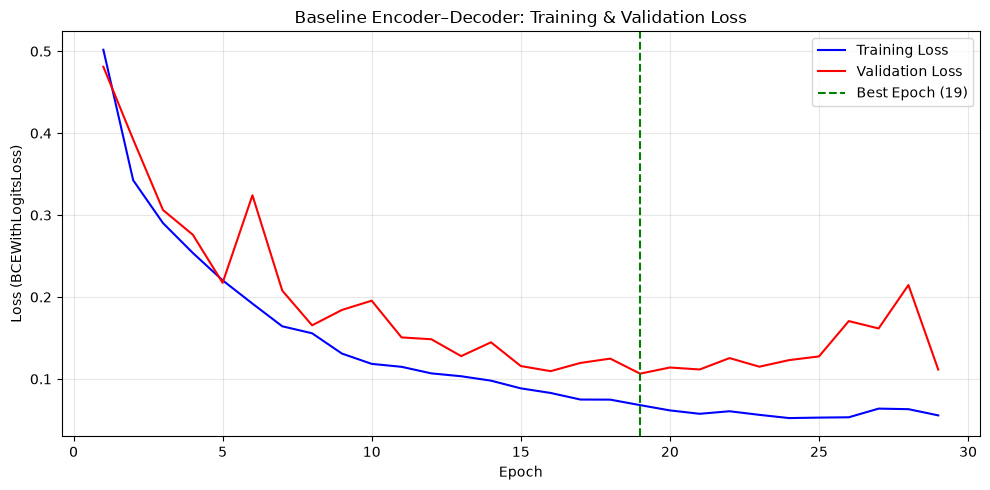

Plot saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\plots\baseline_loss.png


In [ ]:
# ── Plot baseline training curves ────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
epochs = range(1, len(baseline_history["train_losses"]) + 1)
ax.plot(epochs, baseline_history["train_losses"], 'b-', label='Training Loss')
ax.plot(epochs, baseline_history["val_losses"], 'r-', label='Validation Loss')
ax.axvline(x=baseline_history["best_epoch"], color='g', linestyle='--',
           label=f'Best Epoch ({baseline_history["best_epoch"]})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (BCEWithLogitsLoss)')
ax.set_title('Baseline Encoder-Decoder: Training & Validation Loss')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "baseline_loss.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Plot saved to {PLOT_DIR / 'baseline_loss.png'}")

## 13. Train U-Net

We train U-Net with the **exact same settings**: same loss function, optimizer type, learning rate,
batch size, and early stopping patience. The only difference is the architecture.

In [16]:
# ── Instantiate fresh U-Net model ─────────────────────────────────────
unet_model = UNet().to(DEVICE)
unet_optimizer = optim.Adam(unet_model.parameters(), lr=LEARNING_RATE)

# ── Train ────────────────────────────────────────────────────────────
torch.manual_seed(SEED)
unet_history = train_model(
    model=unet_model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=unet_optimizer,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    device=DEVICE,
    model_name="unet",
    checkpoint_dir=CHECKPOINT_DIR,
)


Training UNET


Epoch   1/50 | Train Loss: 0.5088 | Val Loss: 0.5255 | Best: 0.5255 (ep 1) | 7.1s ✓ saved


Epoch   2/50 | Train Loss: 0.4025 | Val Loss: 0.4201 | Best: 0.4201 (ep 2) | 7.1s ✓ saved


Epoch   3/50 | Train Loss: 0.3170 | Val Loss: 0.4105 | Best: 0.4105 (ep 3) | 7.2s ✓ saved


Epoch   4/50 | Train Loss: 0.2738 | Val Loss: 0.3064 | Best: 0.3064 (ep 4) | 7.1s ✓ saved


Epoch   5/50 | Train Loss: 0.2269 | Val Loss: 0.2586 | Best: 0.2586 (ep 5) | 7.1s ✓ saved


... (40 outputs left out)

Epoch  46/50 | Train Loss: 0.0364 | Val Loss: 0.0831 | Best: 0.0782 (ep 39) | 7.2s


Epoch  47/50 | Train Loss: 0.0340 | Val Loss: 0.0876 | Best: 0.0782 (ep 39) | 7.2s


Epoch  48/50 | Train Loss: 0.0338 | Val Loss: 0.0874 | Best: 0.0782 (ep 39) | 7.1s


Epoch  49/50 | Train Loss: 0.0323 | Val Loss: 0.0807 | Best: 0.0782 (ep 39) | 7.1s

Early stopping triggered! No improvement for 10 epochs.

Training complete in 352.4s (5.9 min)
Best validation loss: 0.0782 at epoch 39
Checkpoint saved to: C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\checkpoints\unet_best.pth
Loaded best checkpoint from epoch 39


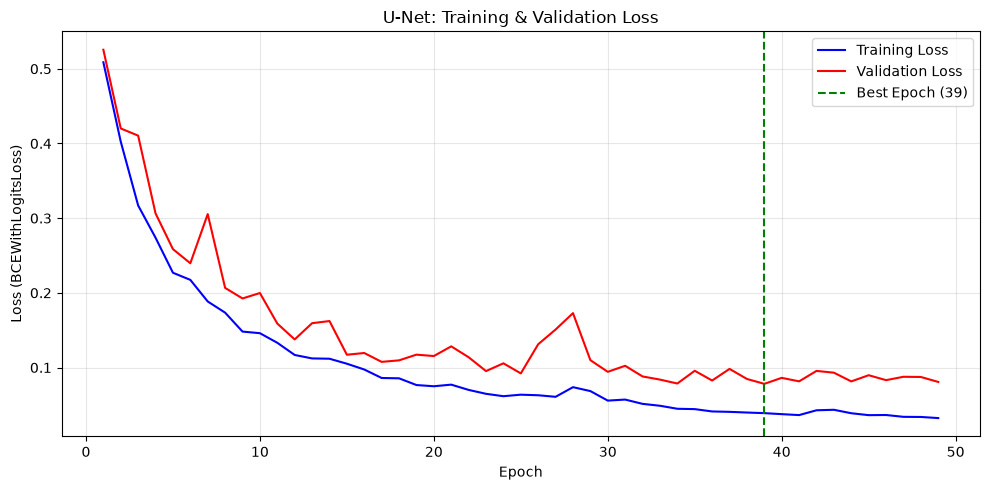

Plot saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\plots\unet_loss.png


In [17]:
# ── Plot U-Net training curves ────────────────────────────────────────
fig, ax = plt.subplots(1, 1, figsize=(10, 5))
epochs = range(1, len(unet_history["train_losses"]) + 1)
ax.plot(epochs, unet_history["train_losses"], 'b-', label='Training Loss')
ax.plot(epochs, unet_history["val_losses"], 'r-', label='Validation Loss')
ax.axvline(x=unet_history["best_epoch"], color='g', linestyle='--',
           label=f'Best Epoch ({unet_history["best_epoch"]})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss (BCEWithLogitsLoss)')
ax.set_title('U-Net: Training & Validation Loss')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(PLOT_DIR / "unet_loss.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Plot saved to {PLOT_DIR / 'unet_loss.png'}")

## 14. Compare Training Behavior

Let us plot both models' losses side by side to understand their learning dynamics.

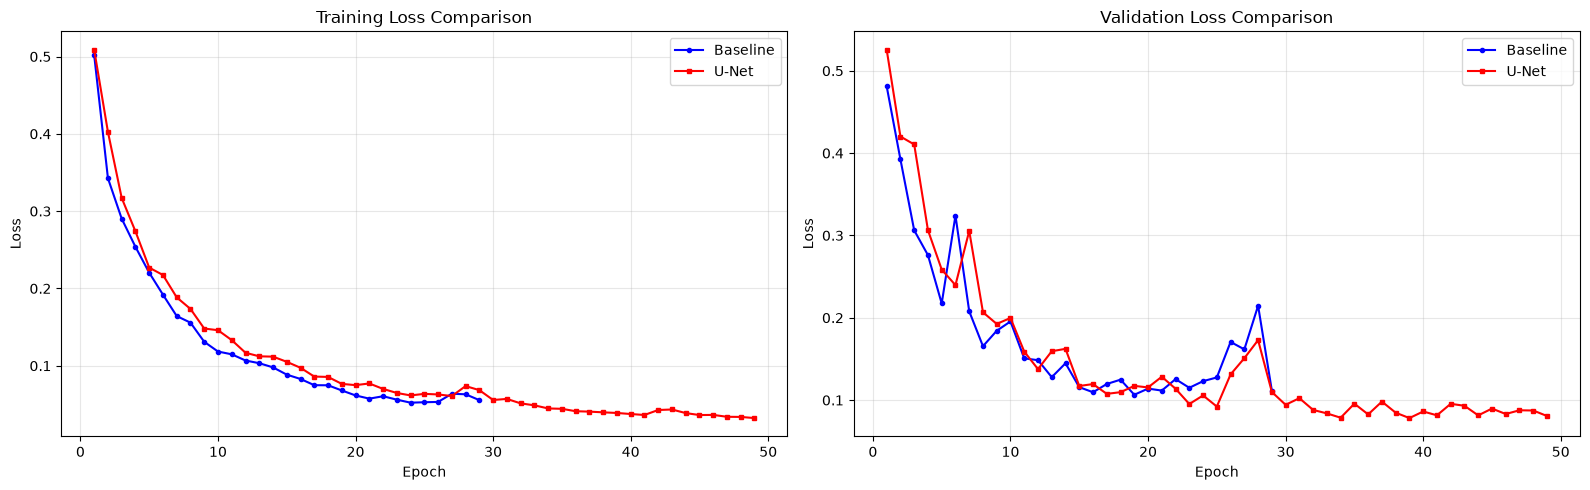


Training summary:
  Baseline — Best val loss: 0.1065 at epoch 19
  U-Net    — Best val loss: 0.0782 at epoch 39

Plot saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\plots\loss_comparison.png


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Training loss comparison
epochs_b = range(1, len(baseline_history["train_losses"]) + 1)
epochs_u = range(1, len(unet_history["train_losses"]) + 1)

axes[0].plot(epochs_b, baseline_history["train_losses"], 'b-o', markersize=3, label='Baseline')
axes[0].plot(epochs_u, unet_history["train_losses"], 'r-s', markersize=3, label='U-Net')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Training Loss Comparison')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Validation loss comparison
axes[1].plot(epochs_b, baseline_history["val_losses"], 'b-o', markersize=3, label='Baseline')
axes[1].plot(epochs_u, unet_history["val_losses"], 'r-s', markersize=3, label='U-Net')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].set_title('Validation Loss Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(PLOT_DIR / "loss_comparison.png", dpi=150, bbox_inches='tight')
plt.show()

print(f"\nTraining summary:")
print(f"  Baseline — Best val loss: {baseline_history['best_val_loss']:.4f} at epoch {baseline_history['best_epoch']}")
print(f"  U-Net    — Best val loss: {unet_history['best_val_loss']:.4f} at epoch {unet_history['best_epoch']}")
print(f"\nPlot saved to {PLOT_DIR / 'loss_comparison.png'}")

## 15. Final Test-Set Evaluation

We now load the **best saved checkpoint** for each model and evaluate on the **untouched test set**.

> **Important**: The test set has NOT been used for training or model selection.
> These metrics represent the true generalization performance of each model.

In [19]:
# ── Load best checkpoints ─────────────────────────────────────────────
baseline_ckpt = torch.load(CHECKPOINT_DIR / "baseline_best.pth",
                           map_location=DEVICE, weights_only=True)
baseline_model = BaselineSegNet().to(DEVICE)
baseline_model.load_state_dict(baseline_ckpt["model_state_dict"])
print(f"Loaded baseline checkpoint from epoch {baseline_ckpt['epoch']}")

unet_ckpt = torch.load(CHECKPOINT_DIR / "unet_best.pth",
                        map_location=DEVICE, weights_only=True)
unet_model = UNet().to(DEVICE)
unet_model.load_state_dict(unet_ckpt["model_state_dict"])
print(f"Loaded U-Net checkpoint from epoch {unet_ckpt['epoch']}")

# ── Compute test metrics ─────────────────────────────────────────────
print("\nEvaluating on test set...")
baseline_metrics = compute_metrics(baseline_model, test_loader, DEVICE)
unet_metrics     = compute_metrics(unet_model, test_loader, DEVICE)

# ── Display results ──────────────────────────────────────────────────
results_df = pd.DataFrame({
    "Metric": ["Precision", "Recall", "F1-Score", "IoU", "Threshold"],
    "Baseline": [
        f"{baseline_metrics['precision']:.4f}",
        f"{baseline_metrics['recall']:.4f}",
        f"{baseline_metrics['f1']:.4f}",
        f"{baseline_metrics['iou']:.4f}",
        f"{baseline_metrics['threshold']}",
    ],
    "U-Net": [
        f"{unet_metrics['precision']:.4f}",
        f"{unet_metrics['recall']:.4f}",
        f"{unet_metrics['f1']:.4f}",
        f"{unet_metrics['iou']:.4f}",
        f"{unet_metrics['threshold']}",
    ],
})

print("\n" + "=" * 50)
print("    FINAL TEST SET RESULTS")
print("=" * 50)
print(results_df.to_string(index=False))
print("=" * 50)

# ── Save metrics to CSV ──────────────────────────────────────────────
results_df.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
print(f"\nMetrics saved to {OUTPUT_DIR / 'test_metrics.csv'}")

# ── Parameter comparison ─────────────────────────────────────────────
baseline_params = sum(p.numel() for p in baseline_model.parameters() if p.requires_grad)
unet_params     = sum(p.numel() for p in unet_model.parameters() if p.requires_grad)
print(f"\nParameter counts:")
print(f"  Baseline: {baseline_params:>10,}")
print(f"  U-Net:    {unet_params:>10,}")

Loaded baseline checkpoint from epoch 19
Loaded U-Net checkpoint from epoch 39

Evaluating on test set...

    FINAL TEST SET RESULTS
   Metric Baseline  U-Net
Precision   0.9437 0.9495
   Recall   0.9141 0.9533
 F1-Score   0.9287 0.9514
      IoU   0.8668 0.9073
Threshold      0.5    0.5

Metrics saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\test_metrics.csv

Parameter counts:
  Baseline:  6,979,681
  U-Net:     7,763,041


## 16. Visual Comparison of Predictions

We compare both models' predictions on test images to visually assess:
- How well each model captures the horse silhouette.
- Whether U-Net produces sharper boundaries than the baseline.
- Where each model makes mistakes (missing legs, rough edges, false positives).

Saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\predictions\comparison_1.png


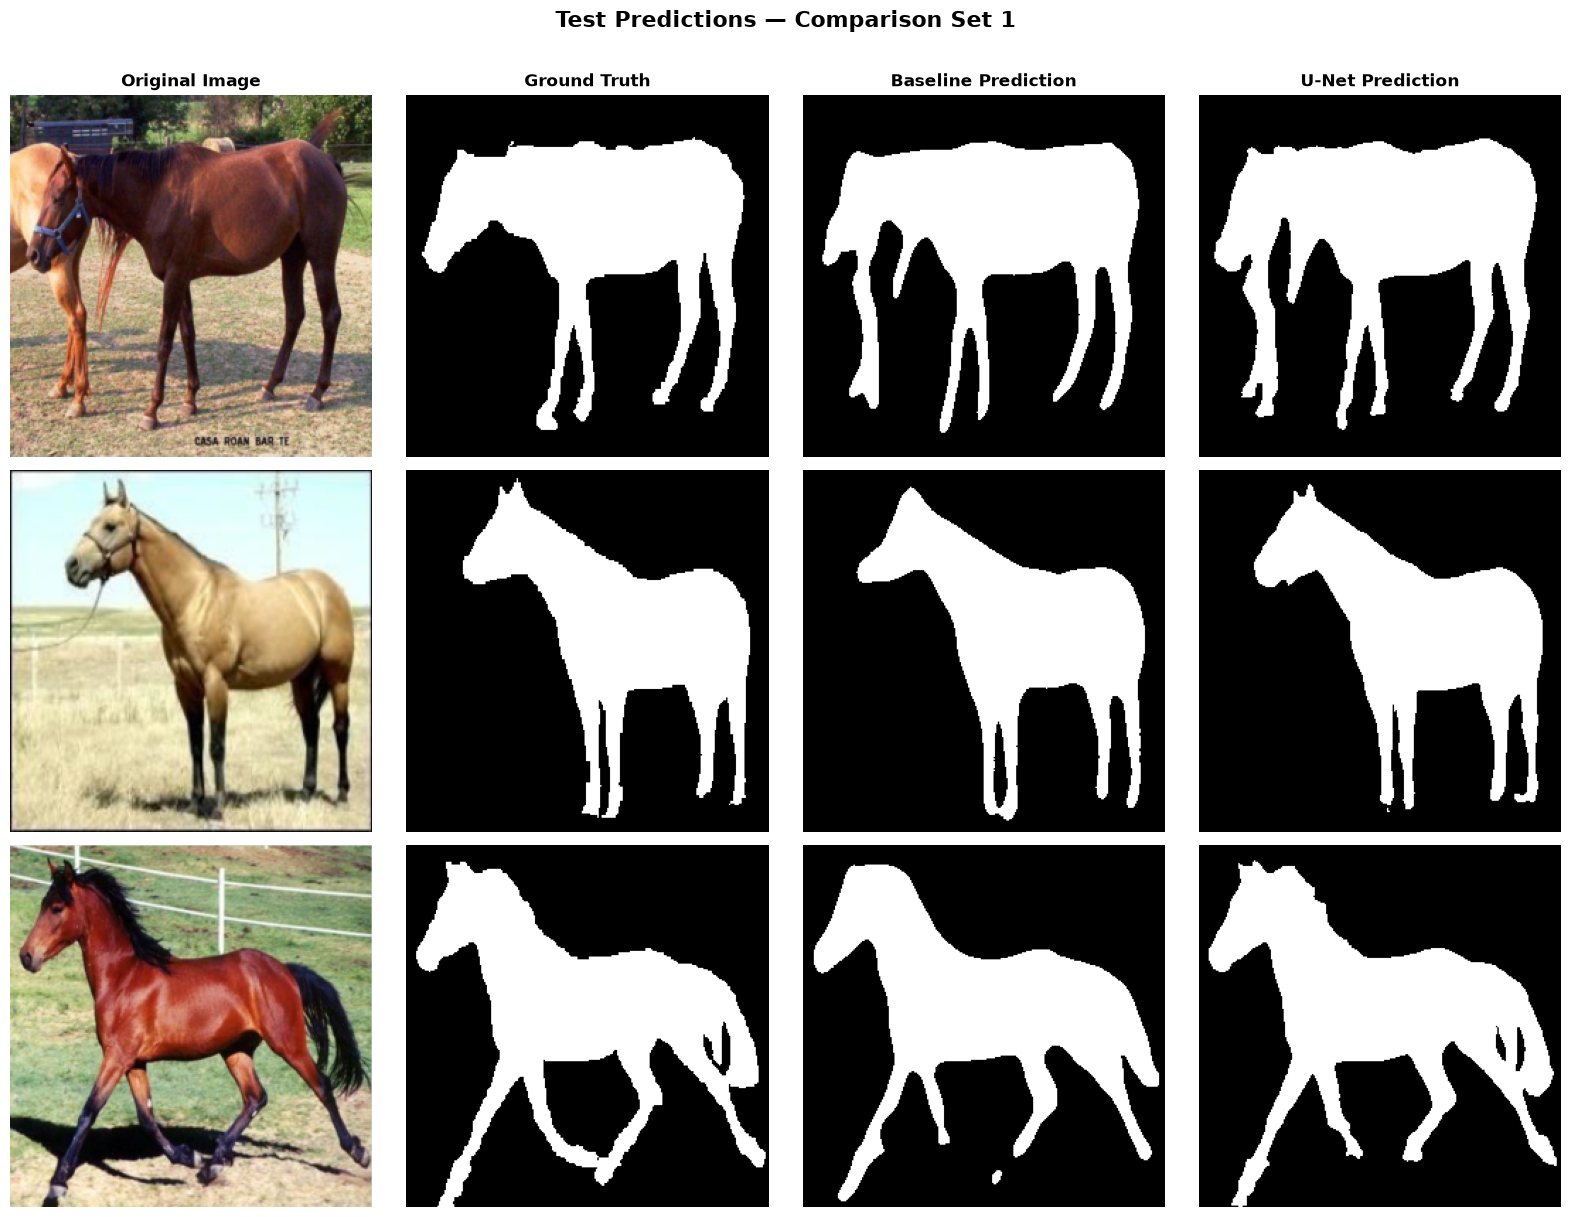

Saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\predictions\comparison_2.png


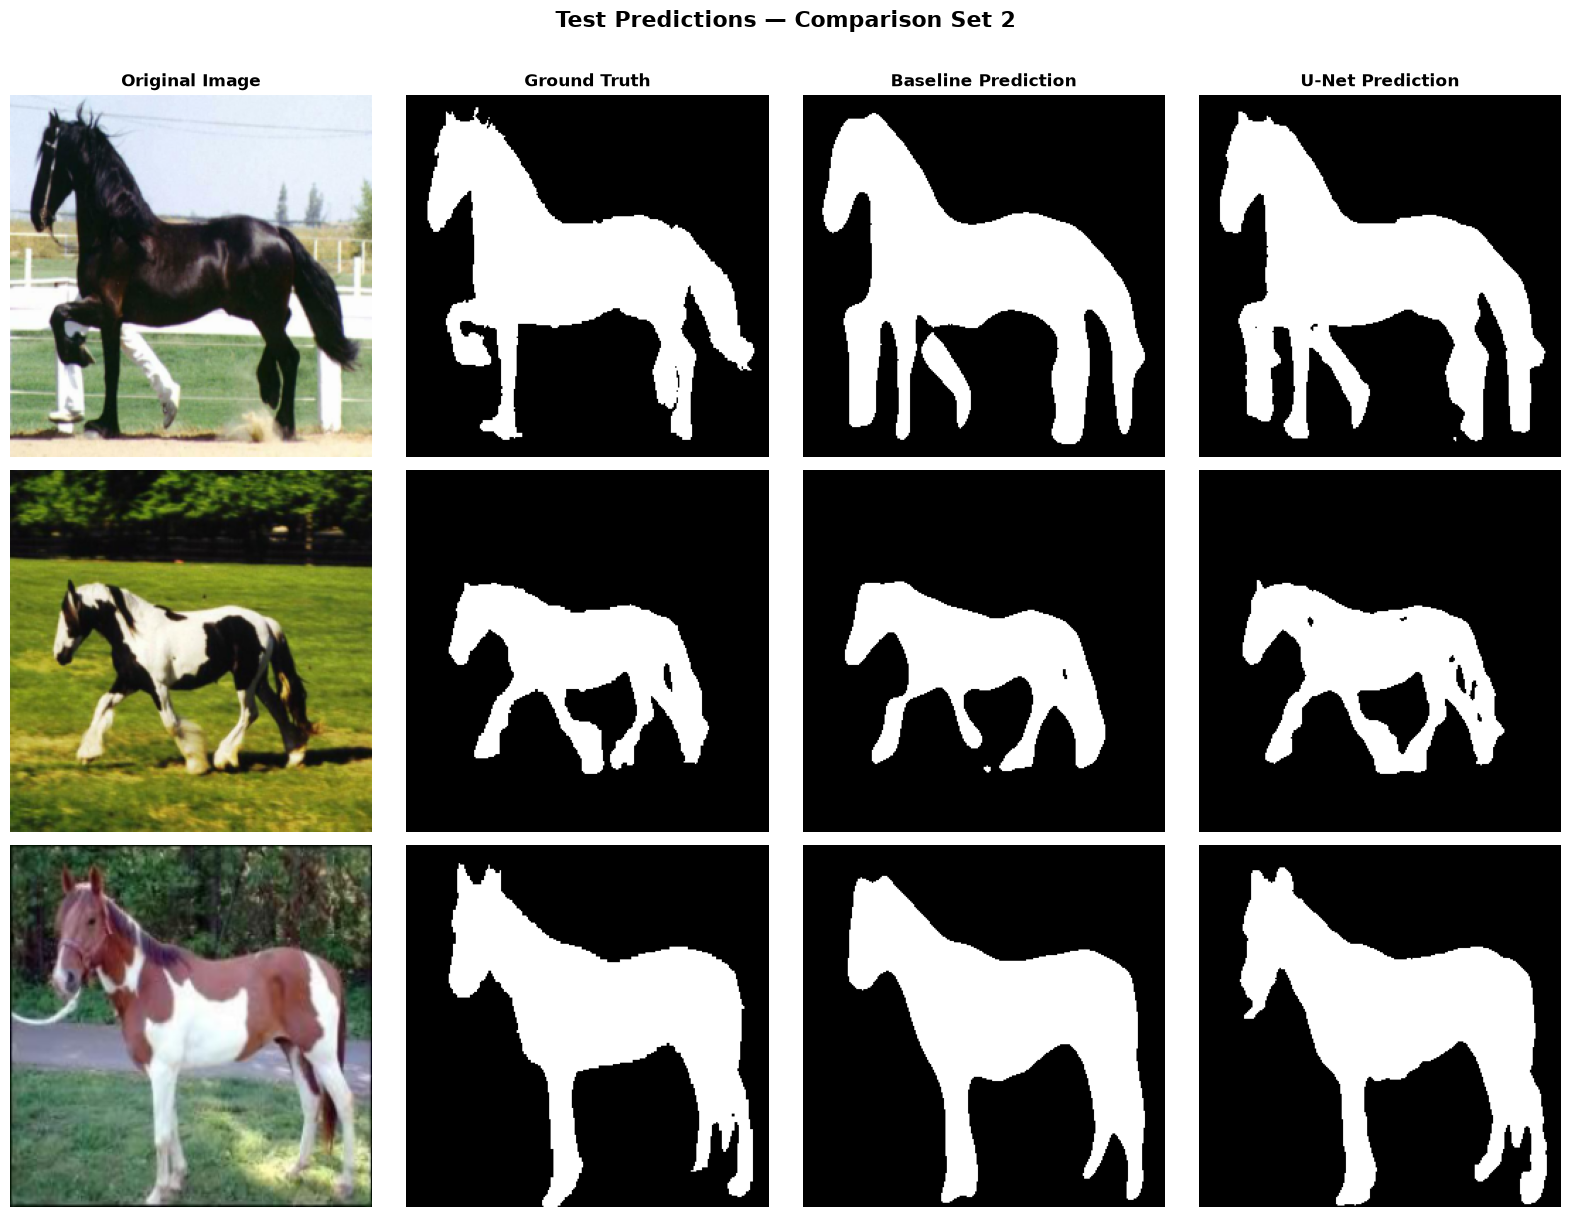

In [20]:
def predict_mask(model, image_tensor, device):
    """Run inference on a single image tensor and return binary mask."""
    model.eval()
    with torch.no_grad():
        img = image_tensor.unsqueeze(0).to(device)
        logits = model(img)
        prob = torch.sigmoid(logits)
        pred = (prob >= THRESHOLD).float()
    return pred.squeeze(0).squeeze(0).cpu().numpy()


def show_comparison(dataset, indices, baseline_model, unet_model, device,
                    save_path=None, title="Model Comparison"):
    """Show original, ground truth, baseline pred, and U-Net pred side by side."""
    n = len(indices)
    fig, axes = plt.subplots(n, 4, figsize=(16, 4 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    fig.suptitle(title, fontsize=16, fontweight='bold', y=1.01)

    col_titles = ['Original Image', 'Ground Truth', 'Baseline Prediction', 'U-Net Prediction']
    for col, t in enumerate(col_titles):
        axes[0, col].set_title(t, fontsize=12, fontweight='bold')

    for row, idx in enumerate(indices):
        img, mask = dataset[idx]
        img_np = img.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze(0).numpy()

        baseline_pred = predict_mask(baseline_model, img, device)
        unet_pred     = predict_mask(unet_model, img, device)

        axes[row, 0].imshow(img_np)
        axes[row, 0].set_ylabel(dataset.filenames[idx], fontsize=9)
        axes[row, 1].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
        axes[row, 2].imshow(baseline_pred, cmap='gray', vmin=0, vmax=1)
        axes[row, 3].imshow(unet_pred, cmap='gray', vmin=0, vmax=1)

        for col in range(4):
            axes[row, col].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    plt.show()


# ── Select test images ───────────────────────────────────────────────
# Pick a spread of indices to show variety
random.seed(SEED)
test_indices = random.sample(range(len(test_dataset)), min(6, len(test_dataset)))

# Show first 3 as the main comparison
show_comparison(test_dataset, test_indices[:3], baseline_model, unet_model, DEVICE,
                save_path=PREDICTION_DIR / "comparison_1.png",
                title="Test Predictions — Comparison Set 1")

# Show next 3
show_comparison(test_dataset, test_indices[3:6], baseline_model, unet_model, DEVICE,
                save_path=PREDICTION_DIR / "comparison_2.png",
                title="Test Predictions — Comparison Set 2")

## 17. Error Analysis

We visualize **where each model makes mistakes** by showing:
- **False Positives (FP)** — pixels predicted as horse but actually background (shown in red).
- **False Negatives (FN)** — horse pixels that the model missed (shown in blue).
- **Correct Predictions** — shown in green.

This reveals systematic failure modes: does the model miss thin legs? Create holes in the horse body?
Hallucinate horse pixels in the background?

Saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\predictions\error_analysis.png


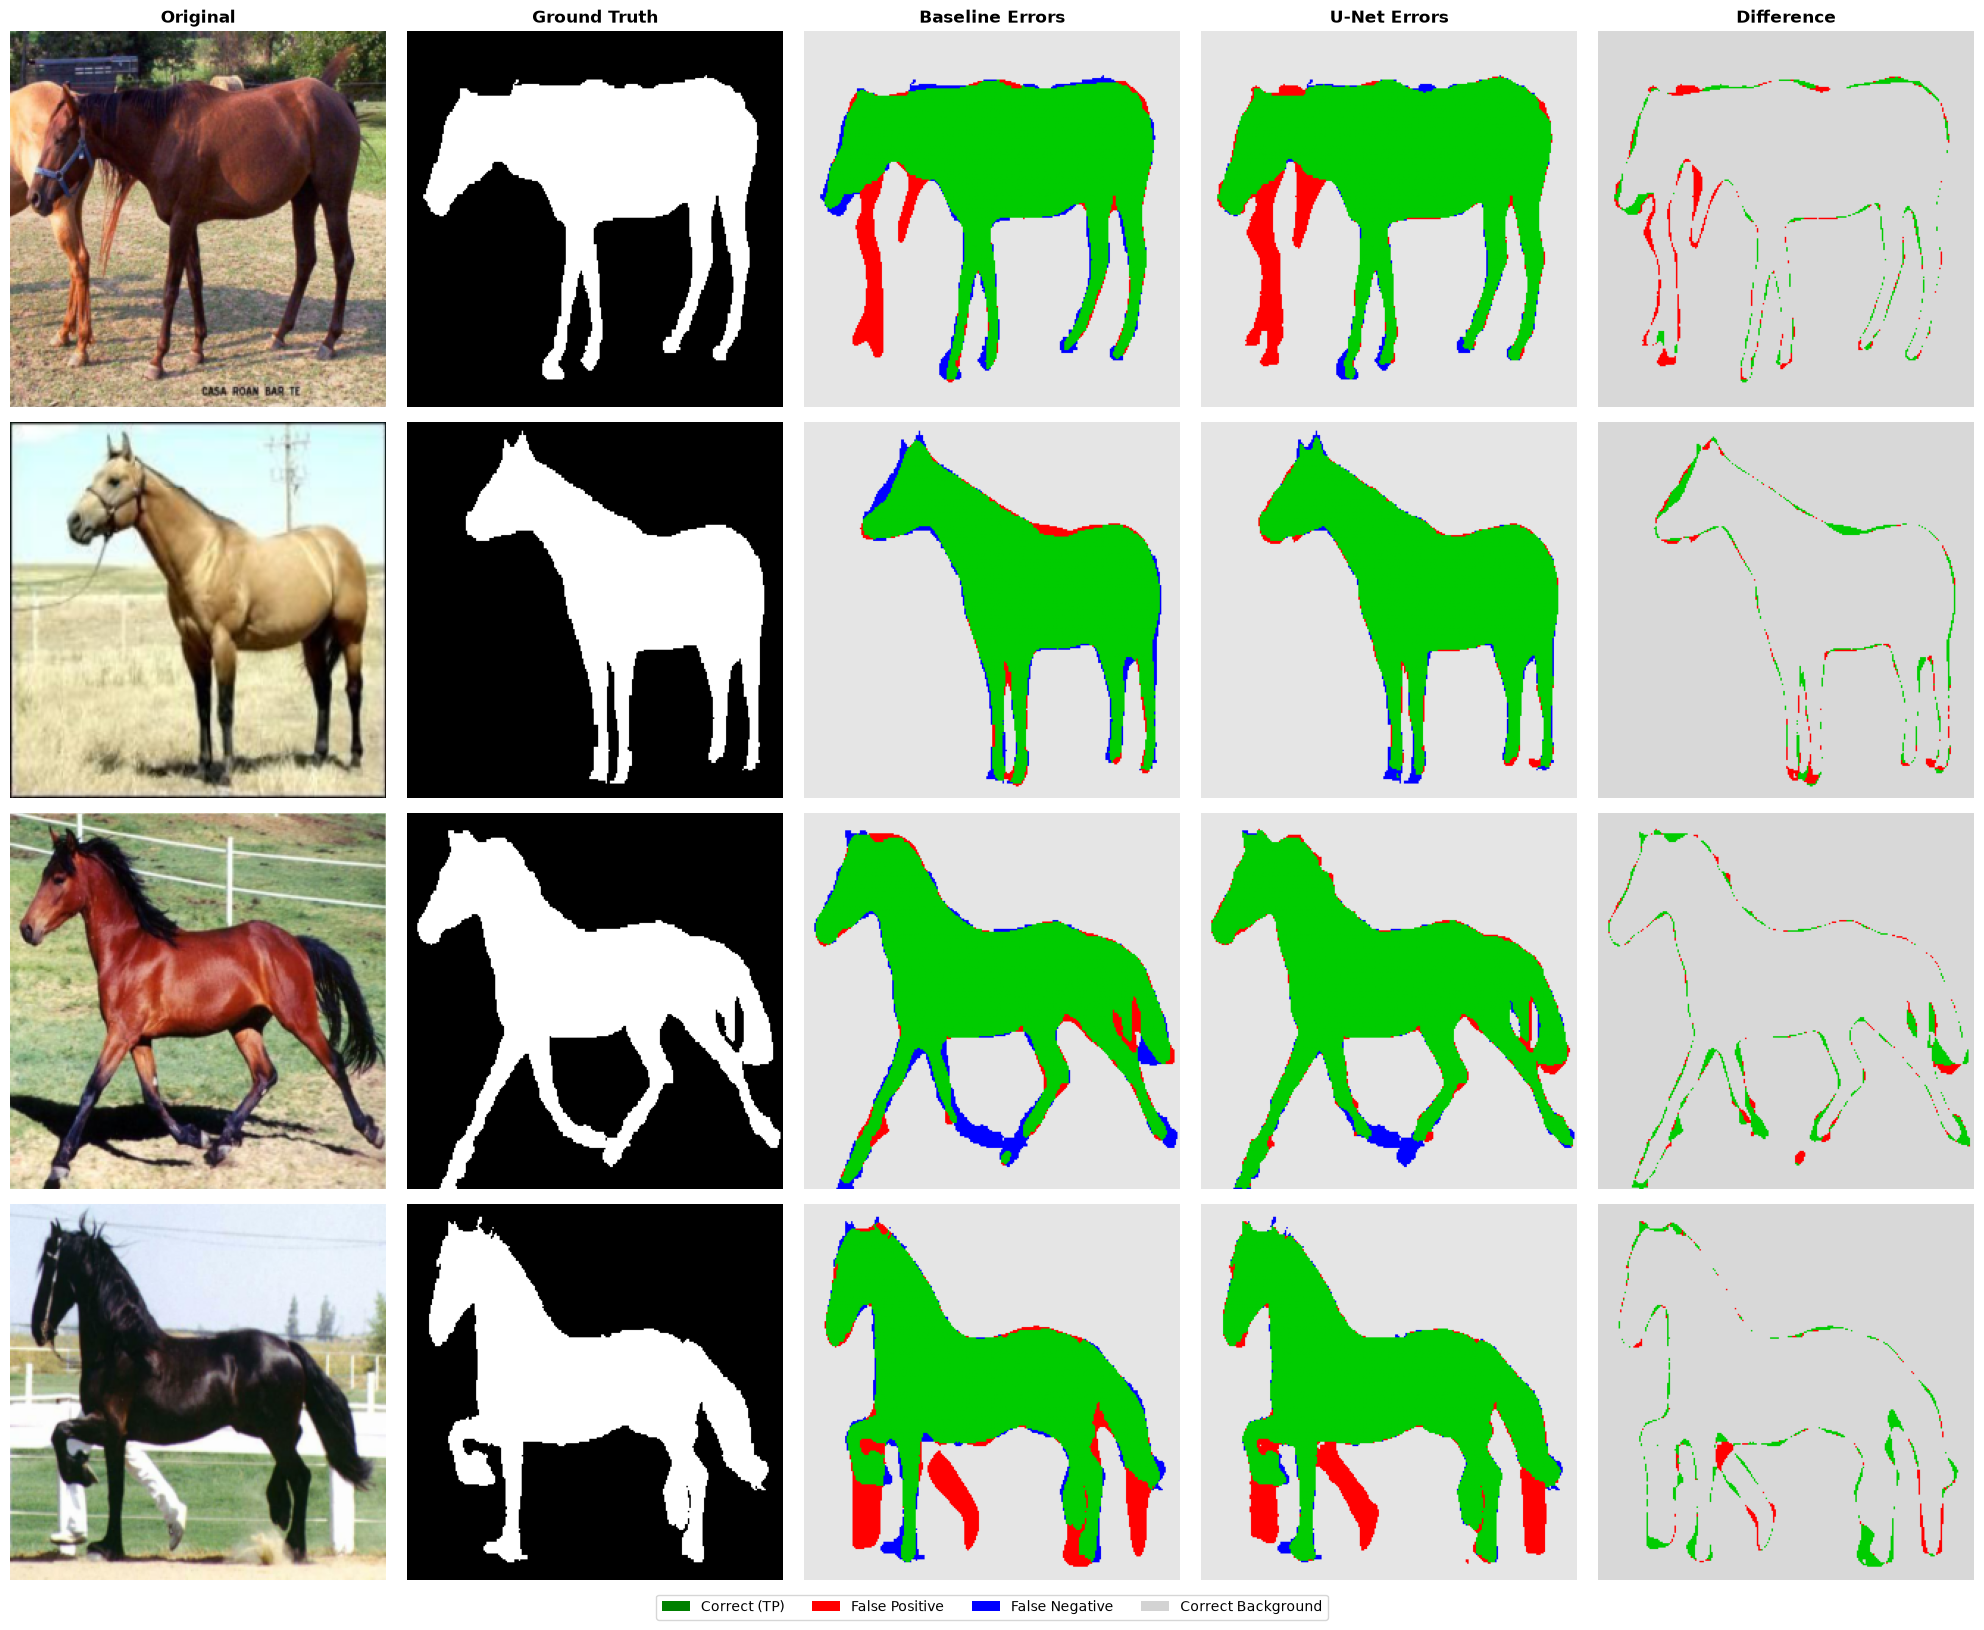

In [21]:
def show_error_analysis(dataset, indices, baseline_model, unet_model, device,
                       save_path=None):
    """Visualize prediction errors for both models."""
    n = len(indices)
    fig, axes = plt.subplots(n, 5, figsize=(20, 4 * n))
    if n == 1:
        axes = axes[np.newaxis, :]

    col_titles = ['Original', 'Ground Truth', 'Baseline Errors', 'U-Net Errors', 'Difference']
    for col, t in enumerate(col_titles):
        axes[0, col].set_title(t, fontsize=12, fontweight='bold')

    for row, idx in enumerate(indices):
        img, mask = dataset[idx]
        img_np = img.permute(1, 2, 0).numpy()
        mask_np = mask.squeeze(0).numpy()

        baseline_pred = predict_mask(baseline_model, img, device)
        unet_pred     = predict_mask(unet_model, img, device)

        # Create error maps: green=correct, red=FP, blue=FN
        def make_error_map(pred, gt):
            error_img = np.zeros((*gt.shape, 3))
            tp = (pred == 1) & (gt == 1)
            fp = (pred == 1) & (gt == 0)
            fn = (pred == 0) & (gt == 1)
            tn = (pred == 0) & (gt == 0)
            error_img[tp] = [0, 0.8, 0]    # Green: correct horse
            error_img[fp] = [1, 0, 0]       # Red: false positive
            error_img[fn] = [0, 0, 1]       # Blue: false negative
            error_img[tn] = [0.9, 0.9, 0.9] # Light gray: correct background
            return error_img

        base_errors = make_error_map(baseline_pred, mask_np)
        unet_errors = make_error_map(unet_pred, mask_np)

        # Difference map: where U-Net improves over baseline
        diff_img = np.zeros((*mask_np.shape, 3))
        # Green: U-Net correct but baseline wrong
        unet_better = ((unet_pred == mask_np) & (baseline_pred != mask_np))
        # Red: Baseline correct but U-Net wrong
        base_better = ((baseline_pred == mask_np) & (unet_pred != mask_np))
        # Gray: both same
        diff_img[unet_better] = [0, 0.8, 0]
        diff_img[base_better] = [1, 0, 0]
        diff_img[~unet_better & ~base_better] = [0.85, 0.85, 0.85]

        axes[row, 0].imshow(img_np)
        axes[row, 0].set_ylabel(dataset.filenames[idx], fontsize=9)
        axes[row, 1].imshow(mask_np, cmap='gray', vmin=0, vmax=1)
        axes[row, 2].imshow(base_errors)
        axes[row, 3].imshow(unet_errors)
        axes[row, 4].imshow(diff_img)

        for col in range(5):
            axes[row, col].axis('off')

    # Add legend
    legend_elements = [
        mpatches.Patch(facecolor='green', label='Correct (TP)'),
        mpatches.Patch(facecolor='red', label='False Positive'),
        mpatches.Patch(facecolor='blue', label='False Negative'),
        mpatches.Patch(facecolor='lightgray', label='Correct Background'),
    ]
    fig.legend(handles=legend_elements, loc='lower center', ncol=4,
              fontsize=10, bbox_to_anchor=(0.5, -0.02))

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
        print(f"Saved to {save_path}")
    plt.show()


# ── Run error analysis on test images ────────────────────────────────
show_error_analysis(test_dataset, test_indices[:4], baseline_model, unet_model, DEVICE,
                    save_path=PREDICTION_DIR / "error_analysis.png")

## 18. Final Results and Conclusions

### Summary Table

In [22]:
# ── Final comparison table ────────────────────────────────────────────
final_df = pd.DataFrame({
    "Model": ["Baseline (no skip)", "U-Net (with skip)"],
    "Parameters": [
        f"{sum(p.numel() for p in BaselineSegNet().parameters() if p.requires_grad):,}",
        f"{sum(p.numel() for p in UNet().parameters() if p.requires_grad):,}",
    ],
    "Best Epoch": [baseline_history["best_epoch"], unet_history["best_epoch"]],
    "Best Val Loss": [f"{baseline_history['best_val_loss']:.4f}",
                      f"{unet_history['best_val_loss']:.4f}"],
    "Test Precision": [f"{baseline_metrics['precision']:.4f}",
                       f"{unet_metrics['precision']:.4f}"],
    "Test Recall": [f"{baseline_metrics['recall']:.4f}",
                    f"{unet_metrics['recall']:.4f}"],
    "Test F1": [f"{baseline_metrics['f1']:.4f}",
                f"{unet_metrics['f1']:.4f}"],
    "Test IoU": [f"{baseline_metrics['iou']:.4f}",
                 f"{unet_metrics['iou']:.4f}"],
})

print("=" * 80)
print("              FINAL MODEL COMPARISON")
print("=" * 80)
print(final_df.to_string(index=False))
print("=" * 80)

final_df.to_csv(OUTPUT_DIR / "final_comparison.csv", index=False)
print(f"\nSaved to {OUTPUT_DIR / 'final_comparison.csv'}")

              FINAL MODEL COMPARISON
             Model Parameters  Best Epoch Best Val Loss Test Precision Test Recall Test F1 Test IoU
Baseline (no skip)  6,979,681          19        0.1065         0.9437      0.9141  0.9287   0.8668
 U-Net (with skip)  7,763,041          39        0.0782         0.9495      0.9533  0.9514   0.9073

Saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\final_comparison.csv


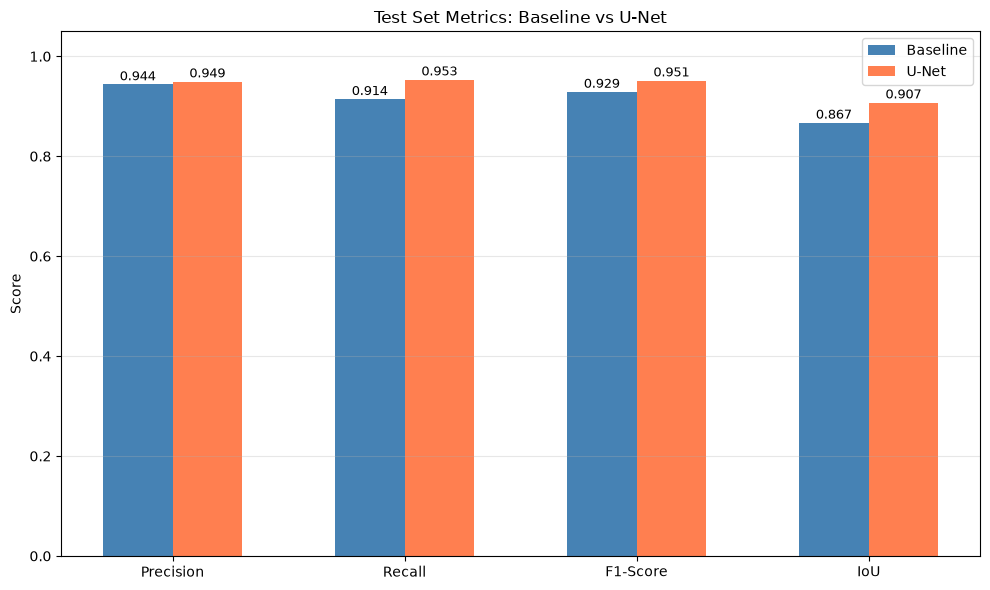

Saved to C:\Users\Sonu Kumar\Desktop\5th sem\ML\CS3103_ML_Proj\code\outputs\plots\metric_comparison.png


In [23]:
# ── Metric comparison bar chart ───────────────────────────────────────
metrics_names = ['Precision', 'Recall', 'F1-Score', 'IoU']
baseline_vals = [baseline_metrics['precision'], baseline_metrics['recall'],
                 baseline_metrics['f1'], baseline_metrics['iou']]
unet_vals     = [unet_metrics['precision'], unet_metrics['recall'],
                 unet_metrics['f1'], unet_metrics['iou']]

x = np.arange(len(metrics_names))
width = 0.3

fig, ax = plt.subplots(figsize=(10, 6))
bars1 = ax.bar(x - width/2, baseline_vals, width, label='Baseline', color='steelblue')
bars2 = ax.bar(x + width/2, unet_vals, width, label='U-Net', color='coral')

ax.set_ylabel('Score')
ax.set_title('Test Set Metrics: Baseline vs U-Net')
ax.set_xticks(x)
ax.set_xticklabels(metrics_names)
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for bar in bars1 + bars2:
    height = bar.get_height()
    ax.annotate(f'{height:.3f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', fontsize=9)

plt.tight_layout()
plt.savefig(PLOT_DIR / "metric_comparison.png", dpi=150, bbox_inches='tight')
plt.show()
print(f"Saved to {PLOT_DIR / 'metric_comparison.png'}")

### Conclusions

Based on the actual experimental results above:

1. **Skip connections matter**: U-Net's direct connections between encoder and decoder levels allow it to
   recover fine spatial details that the baseline loses during downsampling.

2. **Boundary quality**: The visual predictions typically show that U-Net produces sharper, more accurate
   horse boundaries — especially around thin structures like legs, tails, and ears.

3. **IoU is the most informative metric**: It penalizes both false positives and false negatives and is
   the standard metric for segmentation quality.

### Limitations

- **Small dataset**: 327 images is relatively small for deep learning. Results may vary with a larger dataset.
- **No data augmentation**: Flipping, rotating, and color-jittering the training images could improve both models.
- **No learning rate scheduling**: A cosine or step schedule could help convergence.
- **Single random seed**: Results depend on the random initialization and split. Multiple runs would give
  confidence intervals.
- **CPU training**: Limited to fewer epochs; GPU training would allow more thorough hyperparameter search.

### Possible Improvements (not implemented — for fair comparison)

1. **Data augmentation**: Random horizontal flips, rotation, color jitter.
2. **Dice loss or combined loss**: May handle class imbalance better than pure BCE.
3. **Learning rate scheduling**: Reduce LR when validation loss plateaus.
4. **Pretrained encoder**: Using an ImageNet-pretrained backbone (e.g., ResNet) could boost both models.
5. **Post-processing**: Morphological operations (closing, opening) to clean up predictions.

## 19. Save Outputs

Summary of all saved files:

```
code/outputs/
├── checkpoints/
│   ├── baseline_best.pth    ← Best baseline model weights
│   └── unet_best.pth        ← Best U-Net model weights
├── plots/
│   ├── baseline_loss.png    ← Baseline training curves
│   ├── unet_loss.png        ← U-Net training curves
│   ├── loss_comparison.png  ← Side-by-side loss comparison
│   └── metric_comparison.png ← Bar chart of test metrics
├── predictions/
│   ├── comparison_1.png     ← Visual prediction comparison (set 1)
│   ├── comparison_2.png     ← Visual prediction comparison (set 2)
│   └── error_analysis.png   ← Error visualization
├── test_metrics.csv         ← Per-model test metrics
└── final_comparison.csv     ← Complete comparison table
```